# Demo 1: does demographic structure buy forecast skill?

Does an influenza forecast improve when the model knows how people of different ages mix?
Demo 1 asks that of three models of weekly influenza hospital admissions in every US state,
DC and Puerto Rico over the 2025-26 FluSight season. They are identical except in their
age structure:

| model | age groups | mixing between them |
|---|---|---|
| `multi-strata-empirical` | 6 | a measured contact matrix (Mistry et al. 2021) |
| `multi-strata-homogeneous` | 6 | in proportion to each group's size: no age preference |
| `single-strata` | 1 | none: one well-mixed population |

Each is fitted to weekly admissions with an ensemble Kalman filter and forecasts four
weeks ahead from each of 25 weekly forecast dates. All three are scored on the same
target: total admissions in each of 51 jurisdictions (Puerto Rico is forecast but not
scored, as in FluSight, because its season is tropical).

The notebook reads top to bottom:

0. Parameters
1. This introduction
2. Data: the geography, the season, population by age and the CDC observations
3. The compartment model: SIRH once per age group, joined by mixing between groups
4. Parameters, priors and dynamics
5. The simplest model, `single-strata`: one fit and one forecast, explained
6. The other two models, one change each
7. The rolling forecasts: every model at both seeds, then all three models' forecasts
   from the date of section 5
8. Scores
9. Figures: Figure 2, and the supplement's rolling forecasts and calibration panel (a)
10. Tables: the supplement's three Demo 1 tables

Everything that touches epymorph is in this notebook. What is not epymorph is in small
modules beside it: preparing the data (`flu_inputs.py`), writing and reading runs
(`runs.py`), scoring (`scoring.py`), drawing a panel (`plots.py`) and writing a table
(`util.py`).

## 0. Parameters

Where the inputs are, where the runs go, and where the figures and tables are written. A
build overrides these with papermill; the defaults work when the notebook is opened where
it lives, and write no figures or tables, only show them.

In [1]:
data_dir = "../../data"
runs_dir = "../../results/demos/runs/flu"
output_dir = None  # where figures/ and tables/ are written; None shows them only
max_forecast_dates = None  # None for the manuscript; a small number makes a quick test
fit_missing_runs = True  # False stops, rather than fitting for hours, if a run is missing

In [2]:
# Parameters
data_dir = "/Users/jrm846/Documents/Claude/Projects/epymorph-manuscript-pkg/data"
runs_dir = "/Users/jrm846/step10-runs/flu"
output_dir = "/Users/jrm846/Documents/Claude/Projects/epymorph-manuscript-pkg/results/demos"
fit_missing_runs = True


In [3]:
import dataclasses
import time
from datetime import date, timedelta
from pathlib import Path

import epymorph.initializer as init
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from epymorph.adrio.acs5 import PopulationByAge, PopulationByAgeTable
from epymorph.attribute import AttributeDef
from epymorph.compartment_model import edge
from epymorph.data import ipm, mm
from epymorph.data_shape import Shapes
from epymorph.forecasting.dynamic_params import (
    ExponentialTransform,
    GaussianPrior,
    OrnsteinUhlenbeck,
)
from epymorph.forecasting.ensemble_kalman_filter import EnsembleKalmanFilterSimulator
from epymorph.forecasting.filter import ModelLink, Observations
from epymorph.forecasting.filter_plot import PlotRendererPipeline
from epymorph.forecasting.forecast import ForecastSimulator
from epymorph.forecasting.likelihood import PoissonLikelihood
from epymorph.forecasting.pipeline import PipelineConfig, UnknownParam
from epymorph.geography.us_census import StateScope
from epymorph.rume import GPM, MultiStrataRUMEBuilder, SingleStrataRUME
from epymorph.time import EveryNDays, TimeFrame
from joblib import Parallel, delayed
from matplotlib.colors import Normalize
from scipy.stats import binomtest
from sympy import Max

# The parts that are not epymorph.
from manuscript_analysis import flu_inputs, plots, runs, scoring, util
from manuscript_analysis.data import ProvenanceCachedADRIO

plots.use_manuscript_style()

# How the figures and tables name the three models, and their colours: the baseline has
# no added structure (grey), one model adds structure and the data that drives it (blue),
# one adds the structure with the data removed (orange). Demo 2 uses the same roles.
LABELS = {
    "multi-strata-empirical": "empirical mixing",
    "multi-strata-homogeneous": "homogeneous mixing",
    "single-strata": "no age structure",
}
COLORS = {
    "multi-strata-empirical": "tab:blue",
    "multi-strata-homogeneous": "tab:orange",
    "single-strata": "tab:grey",
}

## 2. Data

### Where and when

The geography is a **scope**: every state, DC and Puerto Rico. The **time frame** is the
season: 38 weeks from 2025-09-13. The filter learns from the first ten weeks before it
forecasts anything, as FluSight's own baseline does, so the first forecast is made on
2025-11-22 and the last on 2026-05-09, covering the whole FluSight challenge period.

In [4]:
STATES = [
    "AK", "AL", "AR", "AZ", "CA", "CO", "CT", "DC", "DE", "FL", "GA", "HI", "IA",
    "ID", "IL", "IN", "KS", "KY", "LA", "MA", "MD", "ME", "MI", "MN", "MO", "MS",
    "MT", "NC", "ND", "NE", "NH", "NJ", "NM", "NV", "NY", "OH", "OK", "OR", "PA",
    "PR", "RI", "SC", "SD", "TN", "TX", "UT", "VA", "VT", "WA", "WI", "WV", "WY",
]
UNSCORED = ["PR"]  # forecast but not scored: its influenza season is tropical
ACS_YEAR = 2024
SEASON_START = date(2025, 9, 13)
SEASON_WEEKS = 38
BURN_IN_WEEKS = 10  # assimilated before the first forecast
HORIZON_WEEKS = 4  # how far each forecast reaches

scope = StateScope.in_states(STATES, year=ACS_YEAR)
season = TimeFrame.of(start_date=SEASON_START, duration_days=7 * SEASON_WEEKS)

nodes = list(scope.node_ids)
state_names = list(scope.labels)
fips_of = dict(zip(state_names, nodes))
scored_nodes = [fips_of[state] for state in state_names if state not in UNSCORED]
print(f"{len(nodes)} jurisdictions, {len(scored_nodes)} scored; "
      f"{season.start_date} to {season.end_date}")

52 jurisdictions, 51 scored; 2025-09-13 to 2026-06-05


### Population by age

epymorph's **ADRIOs** fetch data for a scope: here the American Community Survey's
population by age, first the full age table and then one sum per age group. Each is
wrapped in `ProvenanceCachedADRIO`, which saves the result to `data/raw/` with a record of
where and when it came from the first time, and reads that file ever after, so a build
needs no Census API key and always gets the same numbers.

In [5]:
STRATA = flu_inputs.STRATA  # the six age groups, by name
NUM_STRATA = len(STRATA)

age_table = (
    ProvenanceCachedADRIO(
        PopulationByAgeTable(),
        cache_path=Path(data_dir) / "raw" / f"flu-population-by-age-{ACS_YEAR}-{len(STATES)}-states.npz",
        description=(
            f"ACS 5-year population by age (table B01001) per state; "
            f"{ACS_YEAR} vintage; {', '.join(STATES)}"
        ),
    )
    .with_context(scope=scope)
    .inspect().result.astype(np.int64)
)


def frozen_group(name, ages):
    # One age group's population, summed from the table and frozen beside it.
    span = f"{ages[0]}-{ages[1]}" if ages[1] is not None else f"{ages[0]}+"
    return ProvenanceCachedADRIO(
        PopulationByAge(*ages),
        cache_path=Path(data_dir) / "raw" / f"flu-population-{name.removeprefix('age_')}-{ACS_YEAR}-{len(STATES)}-states.npz",
        description=f"ACS 5-year population aged {span} per state; {ACS_YEAR} vintage; {', '.join(STATES)}",
    )


population_by_age = {
    name: frozen_group(name, ages)
    .with_context(scope=scope, params={"population_by_age_table": age_table})
    .inspect().result
    for name, ages in zip(STRATA, flu_inputs.AGE_RANGES)
}
population_by_stratum = np.stack([population_by_age[name] for name in STRATA], axis=1)
population_total = population_by_stratum.sum(axis=1)
print(f"{population_total.sum():,} people; age groups "
      + ", ".join(name.removeprefix("age_") for name in STRATA))

338,156,808 people; age groups 00-04, 05-17, 18-49, 50-64, 65-74, 75-99


### The observations

Weekly influenza hospital admissions by age group, per jurisdiction, from CDC. They were
fetched once and frozen in `data/demos/flu/observations.csv`: CDC revises these series
every week, so fetching them again would move the target every model is scored against.

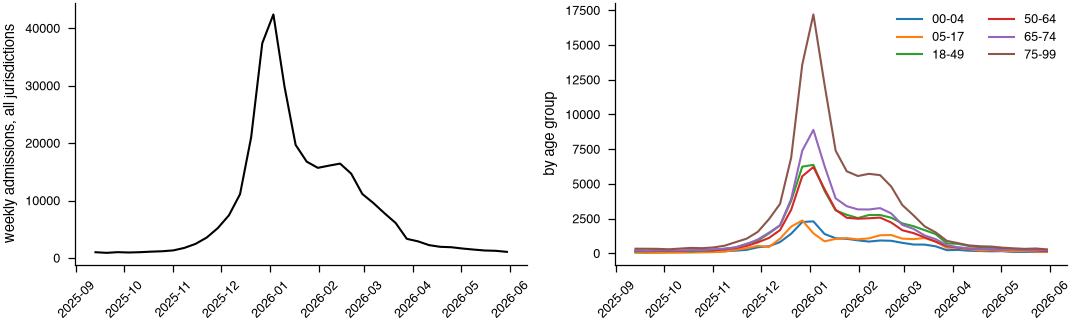

In [6]:
observed = flu_inputs.load_observations(
    Path(data_dir) / "demos" / "flu" / "observations.csv",
    nodes, SEASON_START, SEASON_WEEKS,
)

fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.2), layout="constrained")
axs[0].plot(observed.dates, observed.total.sum(axis=1), color="black")
axs[0].set_ylabel("weekly admissions, all jurisdictions")
for g, name in enumerate(STRATA):
    axs[1].plot(observed.dates, observed.by_age[:, :, g].sum(axis=1), label=name.removeprefix("age_"))
axs[1].set_ylabel("by age group")
axs[1].legend(ncol=2)
for ax in axs:
    ax.tick_params(axis="x", labelrotation=45)
plt.show()

## 3. The disease: SIRH, once per age group

Susceptible, infectious, recovered, hospitalized: SIRH is in epymorph's library of
compartment models, so it does not need defining. The weekly admissions we observe are its
`I -> H` transition.

In [7]:
for event in ipm.SIRH().events:
    print(f"{event.name!s:7} {event.rate}")

S → I   I*S*beta/Max(1, H + I + R + S)
I → H   I*gamma*hospitalization_prob
I → R   I*gamma*(1 - hospitalization_prob)
H → R   H/hospitalization_duration
R → S   R*xi


An age-structured model is built from one copy of that model per age group, each a
**GPM** (a geo-population model: a compartment model, a movement model and an initializer
for one group). Nobody moves between states here, so the movement model is `mm.No()`. The
initializer is a placeholder: the filter is handed each realization's starting
compartments directly.

In [8]:
SEED_RATIOS = np.array([900, 1, 200, 0], dtype=np.int64)  # S, I, R, H; a placeholder

age_groups = [
    GPM(name=name, ipm=ipm.SIRH(), mm=mm.No(), init=init.Proportional(ratios=SEED_RATIOS))
    for name in STRATA
]

### How the age groups mix

Six separate SIRH models would be six separate epidemics. What joins them is
**transmission between age groups**, which a multi-strata model declares as extra edges,
`meta_edges`, alongside the six copies. The force of infection on age group `i` is

$$\lambda_i = q\,\eta_i \sum_j C_{ij}\,\frac{I_j}{N_j},$$

where $C_{ij}$ is how much group `i` contacts group `j`, `q` is transmissibility, and
$\eta_i$ is a per-group correction the filter estimates. These edges carry **all** of the
transmission, so each copy's own `beta` is set to zero.

epymorph has no data shape yet for a matrix per state, so the 36 entries of $C$ are
declared as 36 parameters, `contact_0_0` to `contact_5_5`, each one value per state.

In [9]:
class AgeMixing(MultiStrataRUMEBuilder):
    strata = tuple(age_groups)

    meta_requirements = (
        *[
            AttributeDef(name=f"contact_{i}_{j}", type=float, shape=Shapes.N,
                         comment=f"normalized contacts/day, stratum {i} with stratum {j}")
            for i in range(NUM_STRATA)
            for j in range(NUM_STRATA)
        ],
        AttributeDef(name="q", type=float, shape=Shapes.TxN),
        *[AttributeDef(name=f"eta_{i}", type=float, shape=Shapes.TxN)
          for i in range(NUM_STRATA)],
    )

    def meta_edges(self, symbols):
        compartments = [symbols.strata_compartments(name) for name in STRATA]
        populations = [Max(1, sum(group)) for group in compartments]
        (q,) = symbols.requirements("q")

        edges = []
        for i in range(NUM_STRATA):
            S_i, I_i, _, _ = compartments[i]
            (eta_i,) = symbols.requirements(f"eta_{i}")
            rates = []
            for j in range(NUM_STRATA):  # j == i included: within-group contact
                (c_ij,) = symbols.requirements(f"contact_{i}_{j}")
                _, I_j, _, _ = compartments[j]
                rates.append(q * eta_i * c_ij * S_i * I_j / populations[j])
            edges.append(edge(S_i, I_i, rate=sum(rates)))
        return edges

The contact matrix $C$ is Mistry et al.'s matrix for the United States, by single year of
age, collapsed onto the six groups and **projected** onto each state's own age
distribution: people keep their preferences for whom to contact, and the state's
populations change how many of each age there are to contact. The alternative,
**homogeneous** mixing, has no preference at all: everyone's contacts are split in
proportion to each group's size. Both are scaled to the same leading eigenvalue, so they
can differ only in the shape of mixing, never in overall transmissibility, which `q` fits.
This is the one thing that distinguishes the two stratified models.

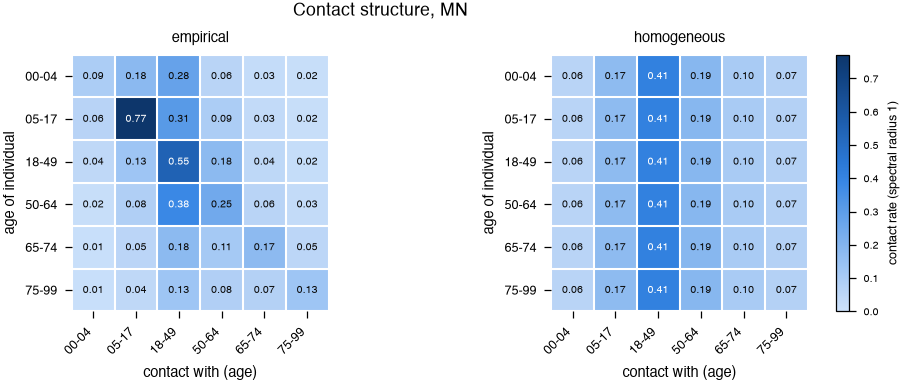

In [10]:
mistry = flu_inputs.mistry_contacts(Path(data_dir) / "raw" / "mistry")
contacts = {  # mixing -> (states, groups, groups)
    mixing: flu_inputs.contact_matrices(mistry, population_by_stratum, mixing)
    for mixing in ("empirical", "homogeneous")
}

FOCUS_STATE = "MN"  # the state every single-state panel is drawn for


def draw_contacts(subfig, state):
    # Both mixing structures for one state, on one colour scale
    matrices = [contacts[mixing][nodes.index(fips_of[state])] for mixing in contacts]
    axs = np.atleast_1d(subfig.subplots(1, len(matrices)))
    shared = Normalize(vmin=0.0, vmax=float(np.max(matrices)))
    labels = [name.removeprefix("age_") for name in STRATA]
    for ax, mixing, matrix in zip(axs, contacts, matrices):
        image = plots.plot_contact_matrix(ax, matrix, labels, title=mixing, norm=shared)
    bar = subfig.colorbar(image, ax=list(axs), fraction=0.046, pad=0.03)
    bar.set_label("contact rate (spectral radius 1)", fontsize=6)
    bar.ax.tick_params(labelsize=5)


fig = plt.figure(figsize=(plots.SINGLE_COLUMN * 2, 2.6), layout="constrained")
draw_contacts(fig, FOCUS_STATE)
fig.suptitle(f"Contact structure, {FOCUS_STATE}")
plt.show()

## 4. Parameters, priors and dynamics

Recovery, waning and the hospital stay are fixed. Severity is fixed per age group: CDC's
case-hospitalization ratios times the fraction of infections that are symptomatic, with
CDC's single 65+ ratio split between the two oldest groups by their observed admission
rates (`flu_inputs.hospitalization_prob`).

In [11]:
GAMMA = 1 / 5.0  # leaving the infectious period: 5 days
XI = 1 / 365  # waning immunity: 1 year
H_DURATION = 5.0  # days in hospital

# The scope holds every jurisdiction, which splitting the national 65+ ratio requires.
hospitalization_prob = flu_inputs.hospitalization_prob(population_by_age)
hospitalization_prob_total = flu_inputs.hospitalization_prob_total(
    hospitalization_prob, population_by_age
)
pd.Series({**hospitalization_prob, "single-strata": hospitalization_prob_total},
          name="infection-hospitalization ratio").round(5)

age_00-04        0.00465
age_05-17        0.00183
age_18-49        0.00374
age_50-64        0.00707
age_65-74        0.03564
age_75-99        0.09659
single-strata    0.01392
Name: infection-hospitalization ratio, dtype: float64

The filter **estimates** transmissibility `q` for each state, and for the stratified
models a correction $\eta_i$ for each age group, all changing over time. Each is
estimated on the log scale, so it stays positive, with:

- a **prior**: what we believe before any data, a normal distribution on the log scale;
- **dynamics**: how it may drift between observations, an Ornstein-Uhlenbeck process that
  wanders but is pulled back towards its mean.

$\eta_i$ is a correction, not a free parameter: centred on no correction and pulled back
to it quickly. `ExponentialTransform("log_q")` connects the two scales: the model's `q`
is `exp(log_q)`, and `log_q` is what the filter estimates.

In [12]:
def log_scale_unknown(mean, prior_sd, damping, ou_sd):
    return UnknownParam(
        prior=GaussianPrior(mean=mean, standard_deviation=prior_sd),
        dynamics=OrnsteinUhlenbeck(damping=damping, mean=mean, standard_deviation=ou_sd),
    )


LOG_Q_MEAN = float(np.log(0.25))  # q = R0 * gamma, so a prior R0 of 1.25
log_q = log_scale_unknown(LOG_Q_MEAN, prior_sd=0.15, damping=1 / 35, ou_sd=0.15)
single_unknowns = {"ipm::log_q": log_q}
stratified_unknowns = {
    "meta::ipm::log_q": log_q,
    **{
        f"meta::ipm::log_eta_{i}": log_scale_unknown(0.0, prior_sd=0.15, damping=1 / 10, ou_sd=0.05)
        for i in range(NUM_STRATA)
    },
}


def stratified_params(mixing):
    # Every parameter the age-mixing model requires; `mixing` is the only thing that varies.
    return {
        "*::ipm::beta": 0.0,  # the meta edges carry all the transmission
        "*::ipm::gamma": GAMMA,
        "*::ipm::xi": XI,
        "*::ipm::hospitalization_duration": H_DURATION,
        "meta::ipm::q": ExponentialTransform("log_q"),
        **{f"gpm:{name}::*::population": population_by_age[name] for name in STRATA},
        **{f"gpm:{name}::ipm::hospitalization_prob": hospitalization_prob[name] for name in STRATA},
        **{f"meta::ipm::eta_{i}": ExponentialTransform(f"log_eta_{i}") for i in range(NUM_STRATA)},
        **{
            f"meta::ipm::contact_{i}_{j}": contacts[mixing][:, i, j]
            for i in range(NUM_STRATA)
            for j in range(NUM_STRATA)
        },
    }

The **initial conditions** are uncertain too, so every realization starts from its own
draw. The infectious fraction of each age group is backed out of its first week of
admissions through severity, with log-normal spread; groups that reported no admissions
are seeded from a floor of one. Between 25% and 60% of each state is already immune, the
same in every age group. Drawing them is data preparation, in `flu_inputs.initial_values`.

In [13]:
seeding = flu_inputs.seeding(observed.by_age[0], hospitalization_prob, population_by_stratum)


def stratified_initial_values(realizations, rng):
    return flu_inputs.initial_values(
        realizations, rng, nodes=nodes, seed=seeding,
        population_by_stratum=population_by_stratum, stratified=True,
    )


def single_initial_values(realizations, rng):
    return flu_inputs.initial_values(
        realizations, rng, nodes=nodes, seed=seeding,
        population_by_stratum=population_by_stratum, stratified=False,
    )

## 5. The simplest model: one fit and one forecast

The `single-strata` model treats each state as one well-mixed population. Here it is
fitted up to one date and forecast from there, explained step by step. Section 7 does
exactly this from each of the 25 forecast dates, for all three models.

The date is two weeks before national admissions peaked, so the four-week forecast
straddles the peak: the hardest stretch of a season to forecast.

In [14]:
REALIZATIONS = 300  # the ensemble size
SEED = 0

week_dates = observed.by_age_source["date"][:, 0, 0]  # the week-ending date of each week
peak_week = int(np.argmax(observed.total.sum(axis=1)))
origin_week = peak_week - 2
origin_date = week_dates[origin_week]
fit_window = TimeFrame.of(start_date=SEASON_START, duration_days=7 * origin_week)

print(f"national admissions peaked in the week ending {week_dates[peak_week]}")
print(f"fit {fit_window.start_date} to {fit_window.end_date} ({origin_week} weeks), "
      f"then forecast {HORIZON_WEEKS} weeks from {origin_date}")

national admissions peaked in the week ending 2026-01-03
fit 2025-09-13 to 2025-12-19 (14 weeks), then forecast 4 weeks from 2025-12-20


### The model

A **RUME** (runnable modeling experiment) puts the pieces together: the compartment model,
a movement model, the initializer, the scope, the time frame and the parameters. With one
group, the contact matrix is just `[1]`, so transmission is a single `beta`, which is `q`.
Its severity is the population-weighted average of the six groups', so it starts level
with the stratified models.

In [15]:
single_model = SingleStrataRUME.build(
    ipm=ipm.SIRH(),
    mm=mm.No(),
    init=init.Proportional(ratios=SEED_RATIOS),
    scope=scope,
    time_frame=fit_window,
    params={
        "ipm::beta": ExponentialTransform("log_q"),  # one group, so beta is q
        "ipm::gamma": GAMMA,
        "ipm::xi": XI,
        "ipm::hospitalization_prob": hospitalization_prob_total,
        "ipm::hospitalization_duration": H_DURATION,
        "*::population": population_total,
    },
)

### How the data meet the model

`Observations` says what the model's output is compared with, and how. The `ModelLink`
selects the matching model quantities: every state, the time frame summed into seven-day
weeks, and the `I -> H` transition. The likelihood scores the observed counts against the
model's. The source is the observations themselves, as dated values.

In [16]:
def observations_for(rume, source, transitions):
    return Observations(
        source=source,
        model_link=ModelLink(
            geo=rume.scope.select.all(),
            time=rume.time_frame.select.all().group(EveryNDays(7)).agg("sum"),
            quantity=rume.ipm.select.events(transitions),
        ),
        likelihood=PoissonLikelihood(),
    )

### Fit: the ensemble Kalman filter

The filter runs the model forward as an ensemble of realizations, each with its own
starting state and its own parameter values drawn from the prior. At every observed week
it nudges each realization's compartments and parameters towards the data, in proportion
to how uncertain the ensemble is relative to the observation. What comes out is a fitted
ensemble: the state of the epidemic, and the estimated parameters, as of the last
observed week.

In [17]:
single_fit = EnsembleKalmanFilterSimulator(
    config=PipelineConfig.from_rume(
        rume=single_model,
        num_realizations=REALIZATIONS,
        unknown_params=single_unknowns,
        initial_values=single_initial_values(REALIZATIONS, np.random.default_rng(SEED)),
    ),
    observations=observations_for(single_model, observed.total_source, "I->H"),
).run(rng=np.random.default_rng(SEED))

key = next(k for k in single_fit.estimated_params if str(k).endswith("log_q"))
q_now = np.exp(np.median(single_fit.estimated_params[key][:, -1, :], axis=0))
print(f"estimated q on the last fitted day: median across states {np.median(q_now):.3f}, "
      f"range {q_now.min():.3f} to {q_now.max():.3f}")

estimated q on the last fitted day: median across states 0.289, range 0.265 to 0.379


### Forecast

A forecast is the fitted ensemble run forward with no more data.
`PipelineConfig.from_output` continues from where the filter stopped; `extend_duration` is
how far. Demo 1 keeps the filter's own parameter dynamics over the forecast.

In [18]:
single_forecast = ForecastSimulator(
    PipelineConfig.from_output(single_fit, extend_duration=7 * HORIZON_WEEKS)
).run(rng=np.random.default_rng(SEED + 1))
print(f"events {single_forecast.events.shape} (realizations, days, states, transitions)")

events (300, 28, 52, 5) (realizations, days, states, transitions)


### Reading the forecast out

The result holds every compartment and every transition, per realization, day and state.
epymorph reads weekly admissions out of it with the same selections the `ModelLink` uses
(the weekly sum of the `I → H` transition), summarizes the realizations into quantiles,
and draws them, here for three states.

Below, the filter's fit in grey and the forecast in blue, each a median and its 95%
interval. Every grey week is the model's prediction *before* that week's data was
assimilated, so the fit is a genuine test of the model too. The observations the filter
saw are filled; the ones it did not are hollow.

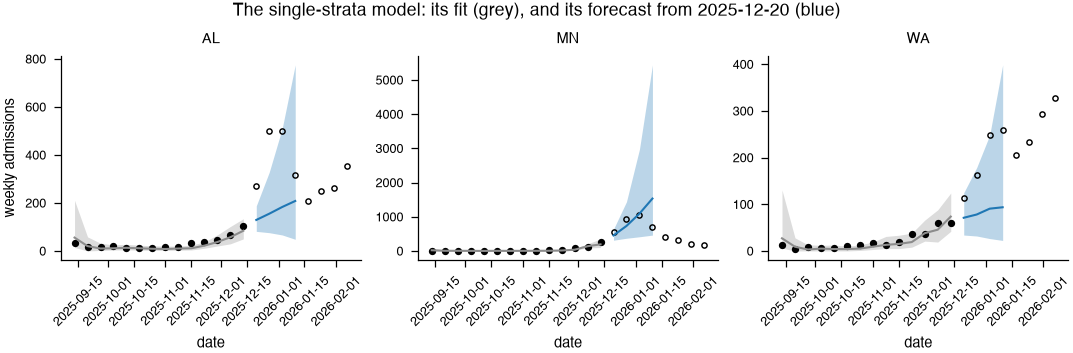

In [19]:
REFERENCE_STATES = ["MN", "AL", "WA"]  # which states the multi-state panels show
end = origin_week + HORIZON_WEEKS + 4  # draw the season to a month past the forecast

fig, axs = plt.subplots(1, len(REFERENCE_STATES), figsize=(plots.DOUBLE_COLUMN, 2.4),
                        sharex=True, layout="constrained")
for output, color in ((single_fit, "0.55"), (single_forecast, "tab:blue")):
    rume = output.rume
    PlotRendererPipeline(output).quantiles_plt(
        axs,
        geo=rume.scope.select.by_state(*REFERENCE_STATES),
        time=rume.time_frame.select.all().group(EveryNDays(7)).agg("sum"),
        quantity=rume.ipm.select.events("I->H"),
        credible_intervals=[95],
        fill_kwargs=[{"color": color, "alpha": 0.3, "linewidth": 0}],
        line_kwargs=[{"color": color}],
        time_format="date",
        legend="off",
    )
for ax in axs:
    node = nodes.index(fips_of[ax.get_title()])  # epymorph titles each panel with its state
    ax.plot(observed.dates[:origin_week], observed.total[:origin_week, node], "o",
            color="black", markersize=2.5)
    ax.plot(observed.dates[origin_week:end], observed.total[origin_week:end, node], "o",
            color="black", markersize=2.5, markerfacecolor="none", markeredgewidth=0.7)
axs[0].set_ylabel("weekly admissions")
fig.suptitle(f"The single-strata model: its fit (grey), and its forecast from {origin_date} (blue)")
plt.show()

## 6. The other two models: one change each

The comparison rests on the models differing only in what the question is about, so each
of the other two is the `single-strata` model with one thing changed.

**`multi-strata-homogeneous`** splits each state into six age groups, joined by
homogeneous mixing. It is fitted to the admissions of each age group, six observed
channels, and scored on their total.

In [20]:
homogeneous_model = AgeMixing().build(
    scope=scope, time_frame=fit_window, params=stratified_params("homogeneous")
)
print(f"{len(homogeneous_model.ipm.compartments)} compartments and "
      f"{len(homogeneous_model.ipm.events)} transitions per state")

24 compartments and 36 transitions per state


**`multi-strata-empirical`** is the same model with the measured contact matrix in place
of homogeneous mixing.

In [21]:
empirical_model = AgeMixing().build(
    scope=scope, time_frame=fit_window, params=stratified_params("empirical")  # was "homogeneous"
)

Both are fitted and forecast with the same calls as the `single-strata` model, with
`stratified_unknowns`, `stratified_initial_values` and the age-group observations
(`observed.by_age_source`, transitions `"I_*->H_*"`). Each takes the better part of four
hours over the season at 300 realizations, so this notebook fits them only once, in the
rolling runs below, and section 7 ends with all three models' forecasts from the date
used above.

## 7. The rolling forecasts

The comparison repeats section 5 from every forecast date. The filter assimilates the
first ten weeks; then, week by week, the model forecasts four weeks ahead and the filter
assimilates one more week. Every forecast uses only the data before its date.

The stratified models forecast each age group, and their total is summed **within each
realization** before it is summarized: quantiles do not add, so the sum of six groups'
medians is not the median of the total. Every step is seeded from the run's seed afresh,
so any one forecast date can be reproduced on its own.

In [22]:
LEVELS = scoring.HUB_QUANTILE_LEVELS  # the 23 quantiles FluSight scores: 1%, 2.5%, 5%, 10%, ..., 99%

origins = list(range(BURN_IN_WEEKS, SEASON_WEEKS - HORIZON_WEEKS + 1))
if max_forecast_dates is not None:
    origins = origins[:max_forecast_dates]
print(f"{len(origins)} forecast dates, {week_dates[origins[0]]} to {week_dates[origins[-1]]}")

AGE_TRANSITIONS = [f"I_{name} → H_{name}" for name in STRATA]

MODELS = {  # name: RUME, observations, unknowns, initial values, observed transitions; slowest first
    "multi-strata-empirical": (empirical_model, observed.by_age_source, stratified_unknowns,
                               stratified_initial_values, AGE_TRANSITIONS),
    "multi-strata-homogeneous": (homogeneous_model, observed.by_age_source, stratified_unknowns,
                                 stratified_initial_values, AGE_TRANSITIONS),
    "single-strata": (single_model, observed.total_source, single_unknowns,
                      single_initial_values, ["I → H"]),
}

25 forecast dates, 2025-11-22 to 2026-05-09


The loop reads weekly admissions out of each result itself: the weekly sum of each
observed transition, the same reading as the `ModelLink` and the figure in section 5, done
on the arrays. That is so it can take every one of FluSight's 23 quantile levels:
epymorph's realization summaries offer levels in steps of 2.5%, and FluSight's include 1%
and 99%.

In [23]:
def weekly(result, rume, transitions, weeks):
    # (realizations, weeks, states, len(transitions)): each transition summed by week
    names = [str(e.name) for e in rume.ipm.events]
    realizations, days, num_nodes, _ = result.events.shape
    shape = (realizations, weeks, days // weeks, num_nodes)
    per_transition = [
        result.events[..., names.index(t)].reshape(shape).sum(axis=2) for t in transitions
    ]
    return np.stack(per_transition, axis=-1)

In [24]:
def rolling_forecast(name, seed):
    # Burn in, then alternate: forecast four weeks, assimilate one more week.
    rume, source, unknowns, initial_values, transitions = MODELS[name]
    stratified = len(transitions) > 1
    quantities = list(STRATA) if stratified else ["total"]
    burn_in = TimeFrame.of(start_date=SEASON_START, duration_days=7 * BURN_IN_WEEKS)
    rume = dataclasses.replace(rume, time_frame=burn_in)
    observations = observations_for(rume, source, "I_*->H_*" if stratified else "I->H")

    fitted_blocks = []  # (posterior, prior, parameters) for each stretch the filter fits

    def assimilate(config, weeks):
        fitted = EnsembleKalmanFilterSimulator(
            config=config, observations=observations
        ).run(rng=np.random.default_rng(seed))
        parameters = np.stack(
            [fitted.estimated_params[key] for key in sorted(fitted.estimated_params, key=str)],
            axis=-1,
        )
        fitted_blocks.append(
            (fitted.posterior_values, weekly(fitted, rume, transitions, weeks), parameters)
        )
        return fitted

    fitted = assimilate(
        PipelineConfig.from_rume(
            rume=rume,
            num_realizations=REALIZATIONS,
            unknown_params=unknowns,
            initial_values=initial_values(REALIZATIONS, np.random.default_rng(seed)),
        ),
        weeks=BURN_IN_WEEKS,
    )

    forecasts = []
    for origin in origins:
        forecast = ForecastSimulator(
            PipelineConfig.from_output(fitted, extend_duration=7 * HORIZON_WEEKS)
        ).run(rng=np.random.default_rng(seed + 1))
        ensemble = weekly(forecast, rume, transitions, HORIZON_WEEKS)
        # A stratified model's file adds the groups' total; the single model's is the total.
        values = runs.with_total(ensemble, LEVELS) if stratified else runs.quantiles(ensemble, LEVELS)
        forecasts.append(runs.forecast_table(
            week_dates[origin], "wk inc influenza hosp", {None: (values, nodes)},
            [*quantities, "total"] if stratified else quantities, LEVELS,
        ))

        if origin != origins[-1]:
            fitted = assimilate(PipelineConfig.from_output(fitted, 7), weeks=1)

    # The fit, week by week, and the estimated parameters, day by day.
    posterior, prior, parameters = (
        np.concatenate(blocks, axis=1) for blocks in zip(*fitted_blocks)
    )
    fit = runs.fit_table(
        posterior, prior, week_dates[:posterior.shape[1]], nodes, quantities, LEVELS,
        add_total=stratified,
    )
    days = [np.datetime64(SEASON_START + timedelta(days=d)) for d in range(parameters.shape[1])]
    names = sorted(str(key) for key in fitted.estimated_params)
    params = runs.params_table(parameters, np.array(days), nodes, names, LEVELS)
    return forecasts, fit, params

Each run is one model at one seed, and is written to `runs_dir/seed<N>/<model>/`. The
manuscript uses two seeds, so that every comparison can be checked for agreement between
them. A run already on disk with the same settings is reused; a missing one is fitted.
The two stratified models take about four hours each, so fitting all six, four at a time,
takes about as long.

In [25]:
SEEDS = (0, 1)
PARALLEL_RUNS = 4  # the demo waits for its slowest model; four starts every slow run at once


def run_folder(name, seed):
    return Path(runs_dir) / f"seed{seed}" / name


def run_settings(seed):
    return {
        "season_start": str(SEASON_START),
        "season_weeks": origins[-1] + HORIZON_WEEKS,
        "burn_in_weeks": BURN_IN_WEEKS,
        "horizon_weeks": HORIZON_WEEKS,
        "num_realizations": REALIZATIONS,
        "seed": seed,
    }


def fit_and_forecast(name, seed):
    # One run: rolling forecasts for one model at one seed, written to disk.
    started = time.monotonic()
    forecasts, fit, params = rolling_forecast(name, seed)
    minutes = (time.monotonic() - started) / 60
    runs.write_run(
        run_folder(name, seed), forecasts=forecasts, fit=fit, params=params,
        info={"model": name, **run_settings(seed), "elapsed_minutes": round(minutes, 1)},
    )
    return f"{name}, seed {seed}: {minutes:.0f} min"


missing = []
for name in MODELS:  # slowest first
    for seed in SEEDS:
        if not runs.run_on_disk(run_folder(name, seed), run_settings(seed)):
            missing.append((name, seed))

print(f"{len(MODELS) * len(SEEDS) - len(missing)} runs on disk, {len(missing)} to fit")
if missing and not fit_missing_runs:
    raise RuntimeError(f"runs missing for {missing}, and fit_missing_runs is False")

# Each run in its own process. joblib can send functions defined in this notebook to
# those processes; the standard library cannot.
finished = Parallel(n_jobs=PARALLEL_RUNS, verbose=10)(
    delayed(fit_and_forecast)(name, seed) for name, seed in missing
)
for line in finished:
    print(line)

0 runs on disk, 6 to fit


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.


[Parallel(n_jobs=4)]: Done   2 out of   6 | elapsed: 227.2min remaining: 454.4min


[Parallel(n_jobs=4)]: Done   3 out of   6 | elapsed: 227.4min remaining: 227.4min


[Parallel(n_jobs=4)]: Done   4 out of   6 | elapsed: 227.8min remaining: 113.9min


multi-strata-empirical, seed 0: 228 min
multi-strata-empirical, seed 1: 226 min
multi-strata-homogeneous, seed 0: 227 min
multi-strata-homogeneous, seed 1: 227 min
single-strata, seed 0: 15 min
single-strata, seed 1: 14 min


[Parallel(n_jobs=4)]: Done   6 out of   6 | elapsed: 241.5min finished


### Three models, one forecast date

The forecasts the three models made from the date of section 5, read back from the runs
at seed 0. The `single-strata` model's differs a little from section 5's, because the
rolling run reached that date one assimilated week at a time.

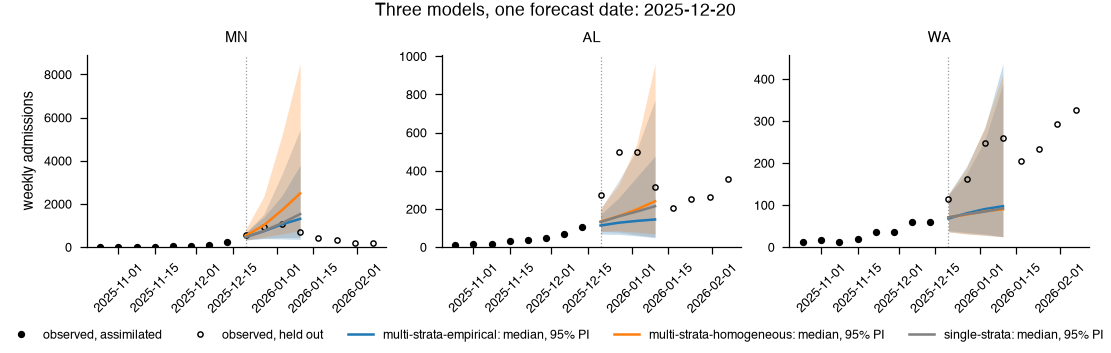

In [26]:
PLOT_LEVELS = (0.025, 0.25, 0.5, 0.75, 0.975)
WINDOW = slice(max(origin_week - 8, 0), origin_week + HORIZON_WEEKS + 4)  # weeks to draw


def forecast_panels(forecasts):
    # One panel per state: total weekly admissions. `forecasts` maps a model to its
    # (weeks, states, levels) quantiles.
    row = []
    for state in REFERENCE_STATES:
        node = nodes.index(fips_of[state])
        row.append({
            "title": state,
            "dates": observed.dates[WINDOW],
            "observed": observed.total[WINDOW, node],
            "origin": observed.dates[origin_week],
            "forecast_dates": observed.dates[origin_week:origin_week + HORIZON_WEEKS],
            "forecasts": {
                model: {level: values[:, node, i] for i, level in enumerate(PLOT_LEVELS)}
                for model, values in forecasts.items()
            },
        })
    return [row]



from_runs = {}
for name in MODELS:
    path = run_folder(name, 0) / "forecasts" / f"{origin_date}.csv"
    if not path.exists():  # a quick test run stops before this date
        continue
    table = pd.read_csv(path, dtype={"location": str})
    table = table[(table["quantity"] == "total") & table["quantile"].isin(PLOT_LEVELS)]
    # Sorted by horizon, location, then quantile, and the nodes are in FIPS order.
    from_runs[name] = table["value"].to_numpy().reshape(HORIZON_WEEKS, len(nodes), len(PLOT_LEVELS))

if from_runs:
    fig, _ = plots.plot_single_forecast_grid(
        forecast_panels(from_runs), colors=COLORS, ylabels="weekly admissions",
        title=f"Three models, one forecast date: {origin_date}",
    )
    plt.show()
else:
    print(f"no run reaches {origin_date}")

## 8. Scores

Every forecast is scored against what was then observed, on total admissions in each of
the 51 scored jurisdictions, with the weighted interval score (WIS) the forecasting hubs
use: roughly, how far the observation fell from the forecast's median and outside its
intervals, with a penalty for width. Lower is better. Following CDC's FluSight
evaluations, it is computed on the log scale, `log(x + 1)`, so California does not count
forty times as much as Wyoming. Each score uses the forecast's median and its 50% and 95%
intervals.

Two models are compared by **relative WIS**, the ratio of their geometric mean scores:
below 1, the model beat the baseline, here `single-strata`.

In [27]:
BASELINE = "single-strata"
SCORE_LEVELS = scoring.SCORE_LEVELS  # the median and the 50% and 95% intervals
DIMS = ["reference_date", "horizon", "location"]  # the axes of a scored forecast

# The observations as a table, with `total`, the sum of the age groups, added.
observation_table = flu_inputs.observation_table(Path(data_dir) / "demos" / "flu" / "observations.csv")


def load_scored(seed):
    # Every model's run at `seed`: its total forecasts at the scored jurisdictions,
    # shaped (forecast dates, horizons, jurisdictions, levels), and what was observed.
    loaded = runs.load_runs(Path(runs_dir) / f"seed{seed}", list(MODELS))
    forecasts, observed_cells = {}, {}
    for name, run in loaded.items():
        rows = run.forecasts
        rows = rows[(rows["quantity"] == "total") & rows["location"].isin(scored_nodes)]
        forecasts[name], coords = runs.quantile_array(rows, DIMS, levels=SCORE_LEVELS)
        observed_cells[name] = runs.align_observations(
            rows, DIMS, observation_table, quantity="total"
        )
    for name in MODELS:  # every model must be scored against the same thing
        assert np.array_equal(observed_cells[name], observed_cells[BASELINE])
    return {"runs": loaded, "forecasts": forecasts, "observed": observed_cells[BASELINE],
            "coords": coords}


def wis(seed_data, scale):
    # scores[model]: one score per (forecast date, horizon, jurisdiction)
    return {
        name: scoring.weighted_interval_score(seed_data["observed"], forecasts, SCORE_LEVELS, scale)
        for name, forecasts in seed_data["forecasts"].items()
    }


def coverage(seed_data, nominal):
    # Whether each observation fell inside the forecast's central interval
    return {
        name: scoring.interval_coverage(seed_data["observed"], forecasts, SCORE_LEVELS, nominal)
        for name, forecasts in seed_data["forecasts"].items()
    }


def relative_by_jurisdiction(scores, model):
    return scoring.relative_wis(scores[model], scores[BASELINE], axis=(0, 1))


seed0, seed1 = load_scored(0), load_scored(1)
scores = wis(seed0, "log")  # the manuscript's scores
scores_seed1 = wis(seed1, "log")  # the same at the second seed
scores_natural = wis(seed0, "natural")  # for the skill table
cover95, cover50 = coverage(seed0, 0.95), coverage(seed0, 0.50)
horizons = seed0["coords"]["horizon"]
scored_order = list(seed0["coords"]["location"])  # the jurisdiction axis, in FIPS order
label_of = dict(zip(nodes, state_names))

for model in ("multi-strata-empirical", "multi-strata-homogeneous"):
    for seed, seed_scores in (("0", scores), ("1", scores_seed1)):
        ratios = relative_by_jurisdiction(seed_scores, model)
        print(f"{model:25s} seed {seed}: relative log WIS "
              f"{float(scoring.relative_wis(seed_scores[model], seed_scores[BASELINE])):.3f}, "
              f"better in {(ratios < 1).sum()} of {len(ratios)}")

multi-strata-empirical    seed 0: relative log WIS 0.961, better in 35 of 51
multi-strata-empirical    seed 1: relative log WIS 0.961, better in 38 of 51
multi-strata-homogeneous  seed 0: relative log WIS 1.046, better in 16 of 51
multi-strata-homogeneous  seed 1: relative log WIS 1.026, better in 22 of 51


## 9. Figures

Each figure is assembled here from panels that `plots.py` draws. With `output_dir` set,
each is saved as PDF and PNG to `output_dir/figures/`, where the manuscript takes them
from.

**Figure 2** has the same four panels as Demo 2's Figure 3: (a) what varies between the
models, (b) forecast skill against horizon, (c) the model fitting its many channels, and
(d) the benefit, distributed over units.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


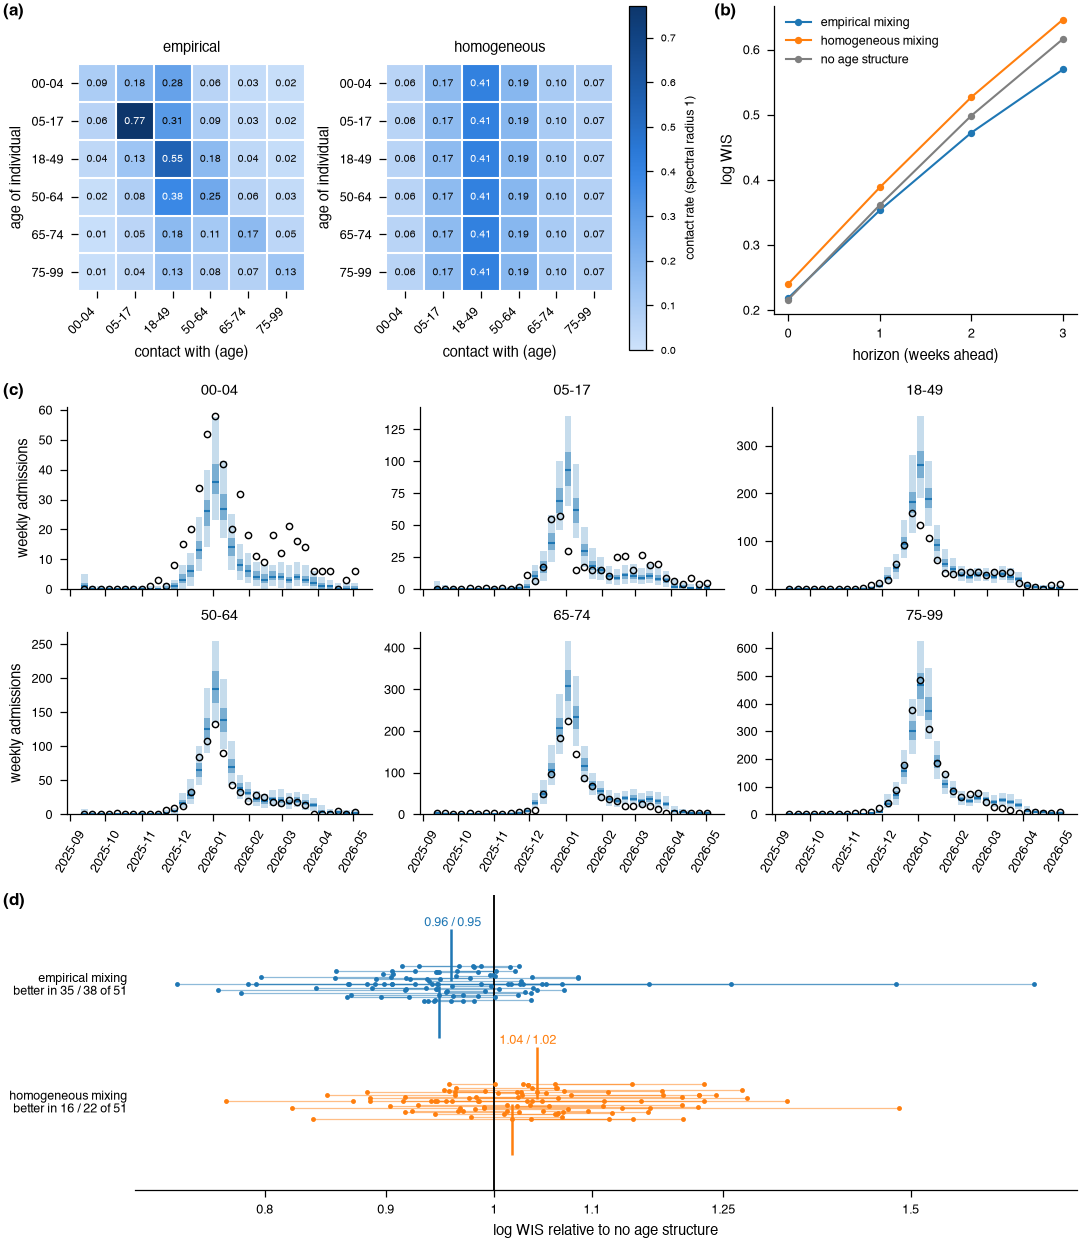

In [28]:
figures_dir = None if output_dir is None else Path(output_dir) / "figures"


def save(fig, name):
    if figures_dir is not None:
        plots.save_figure(fig, name, figures_dir)
    plt.show()


def draw_skill_by_horizon(subfig):
    # (b) Mean log WIS at each horizon
    series = {
        LABELS[model]: scores[model].mean(axis=(0, 2))[np.newaxis, :] for model in MODELS
    }
    plots.plot_line_panels(
        horizons, series, colors={LABELS[model]: COLORS[model] for model in MODELS},
        ylabel=scoring.SCORE_LABELS["log"], xlabel="horizon (weeks ahead)", xticks=horizons,
        legend_loc="upper left",
        figure_width=plots.SINGLE_COLUMN, panel_height=2.3, subfig=subfig,
    )


def draw_fit_by_age(subfig, state, model):
    # (c) The one-week-ahead fit (before each week's update, so a genuine prediction) of
    # each age group. Bars, not a ribbon: each week is a separate prediction.
    fit = seed0["runs"][model].fit
    fit = fit[(fit["series"] == "prior") & (fit["location"] == fips_of[state])]
    panels = []
    for group in STRATA:
        group_fit = fit[fit["quantity"] == group]
        values, coords = runs.quantile_array(group_fit, ["target_end_date"], levels=SCORE_LEVELS)
        dates = pd.to_datetime(coords["target_end_date"])
        seen = observation_table[
            (observation_table["quantity"] == group)
            & (observation_table["location"] == fips_of[state])
            & (observation_table["date"].isin(dates))
        ].sort_values("date")
        panels.append({
            "dates": dates,
            "quantiles": {level: values[:, i] for i, level in enumerate(SCORE_LEVELS)},
            "observed": seen["value"].to_numpy(),
            "color": COLORS[model],
            "title": group.removeprefix("age_"),
        })
    plots.plot_quantile_grid(
        panels, ncols=3, ylabels="weekly admissions",
        figure_width=plots.DOUBLE_COLUMN, panel_height=1.8, subfig=subfig,
    )


def draw_benefit(subfig):
    # (d) Each stratified model's relative log WIS in each jurisdiction, both seeds
    rows = [
        {"label": LABELS[model], "color": COLORS[model],
         "seeds": [relative_by_jurisdiction(scores, model),
                   relative_by_jurisdiction(scores_seed1, model)]}
        for model in ("multi-strata-empirical", "multi-strata-homogeneous")
    ]
    _, axs = plots.panel_grid(1, 1, subfig=subfig, figsize=(plots.ONE_AND_HALF_COLUMN, 2.5))
    plots.plot_ratio_swarm(axs[0, 0], rows, ticks=(0.8, 0.9, 1.0, 1.1, 1.25, 1.5))
    axs[0, 0].set_xlabel(f"{scoring.SCORE_LABELS['log']} relative to {LABELS[BASELINE]}")


fig = plt.figure(figsize=(plots.DOUBLE_COLUMN, 8.3), layout="constrained")
top, channels, benefit = fig.subfigures(3, 1, height_ratios=[2.5, 3.4, 2.4])
structure, skill = top.subfigures(1, 2, width_ratios=[1.9, 1.0])
draw_contacts(structure, FOCUS_STATE)
draw_skill_by_horizon(skill)
draw_fit_by_age(channels, FOCUS_STATE, "multi-strata-empirical")
draw_benefit(benefit)
plots.label_panels([structure, skill, channels, benefit])
save(fig, "fig2-flu-demographic-structure")

**Supplementary: the rolling forecasts** of the empirical-mixing model, (a) by age group
in one state, which is what the model forecasts, and (b) as totals in three states, which
is what is scored. The age groups are a darker blue, so two resolutions of one model do
not read as two models.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


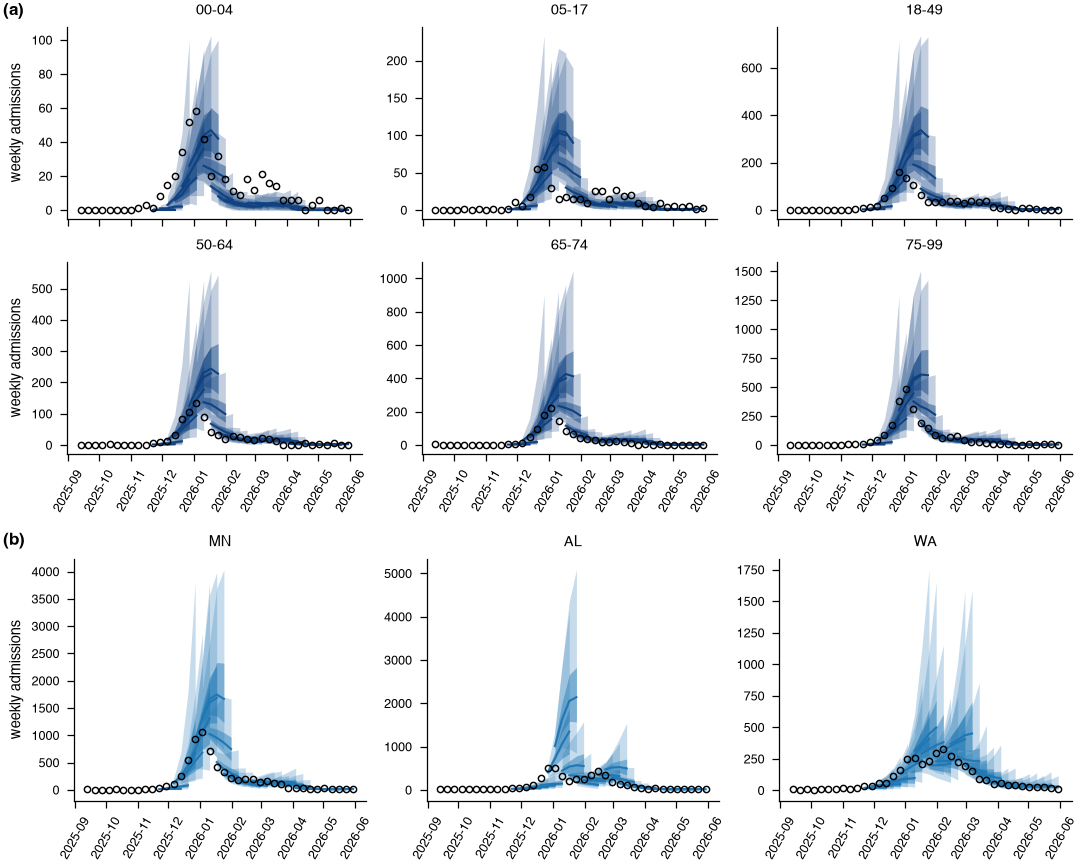

In [29]:
def observed_series(state, quantity):
    seen = observation_table[
        (observation_table["quantity"] == quantity)
        & (observation_table["location"] == fips_of[state])
    ].sort_values("date")
    return seen["date"].to_numpy(), seen["value"].to_numpy()


def draw_rolling_by_age(subfig, state, model, color):
    rows = seed0["runs"][model].forecasts
    rows = rows[rows["location"] == fips_of[state]]
    panels = []
    for group in STRATA:
        values, coords = runs.quantile_array(
            rows[rows["quantity"] == group], ["reference_date", "horizon"], levels=SCORE_LEVELS
        )
        panels.append({
            "origins": coords["reference_date"], "horizons": coords["horizon"], "values": values,
            "observed": observed_series(state, group), "color": color,
            "title": group.removeprefix("age_"),
        })
    plots.plot_rolling_forecast_grid(
        panels, SCORE_LEVELS, ncols=3, ylabels="weekly admissions",
        figure_width=plots.DOUBLE_COLUMN, panel_height=1.7, subfig=subfig,
    )


def draw_rolling_totals(subfig, states, model):
    panels = []
    for state in states:
        panels.append({
            "origins": seed0["coords"]["reference_date"], "horizons": horizons,
            "values": seed0["forecasts"][model][:, :, scored_order.index(fips_of[state]), :],
            "observed": observed_series(state, "total"), "color": COLORS[model], "title": state,
        })
    plots.plot_rolling_forecast_grid(
        panels, SCORE_LEVELS, ylabels="weekly admissions",
        figure_width=plots.DOUBLE_COLUMN, panel_height=2.0, subfig=subfig,
    )


fig = plt.figure(figsize=(plots.DOUBLE_COLUMN, 5.8), layout="constrained")
by_age, totals = fig.subfigures(2, 1, height_ratios=[3.4, 2.2])
draw_rolling_by_age(by_age, FOCUS_STATE, "multi-strata-empirical", plots.FINE_SCALE)
draw_rolling_totals(totals, REFERENCE_STATES, "multi-strata-empirical")
plots.label_panels([by_age, totals])
save(fig, "figS-flu-rolling-forecasts")

**Supplementary: calibration**, how often the observation fell inside each model's 95%
interval, by horizon. The supplement sets it beside Demo 2's as panel (a). All three
models are under-dispersed, which is a limitation of these models, stated in the text.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


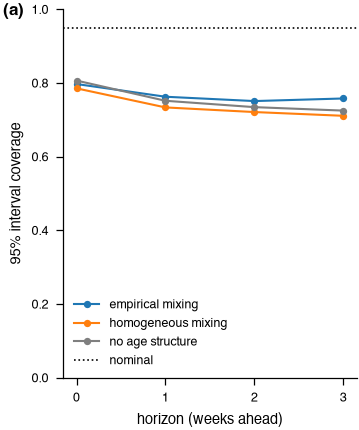

In [30]:
series = {
    LABELS[model]: np.array([[cover95[model][:, h].mean() for h in range(len(horizons))]])
    for model in MODELS
}
fig = plt.figure(figsize=(plots.DOUBLE_COLUMN / 3, 2.9), layout="constrained")
plots.plot_line_panels(
    horizons, series, colors={LABELS[model]: COLORS[model] for model in MODELS},
    ylabel="95% interval coverage", xlabel="horizon (weeks ahead)", xticks=horizons,
    ylim=(0, 1), reference=0.95, reference_label="nominal",
    figure_width=plots.SINGLE_COLUMN, panel_height=2.3, subfig=fig,
)
plots.label_panels([fig], labels=["a"])
save(fig, "figS-calibration-flu")

## 10. Tables

The supplement's three Demo 1 tables. With `output_dir` set, each is written to
`output_dir/tables/` as CSV, to read, and as LaTeX, which the supplement `\input`s. The
LaTeX carries its caption, so a number quoted there cannot drift from the table, and a
header saying it is generated: it is never edited by hand.

In [31]:
tables_dir = None if output_dir is None else Path(output_dir) / "tables"


def write(frame, name, caption, note=None, long=False):
    if tables_dir is not None:
        util.write_table(
            frame, tables_dir, name, caption=caption, note=note, long=long,
            generated_by="demo-flu.ipynb",
            regenerate="just build",
        )
    display(frame)


def skill_columns(scores, label):
    return pd.DataFrame(
        {
            label: [scores[m].mean() for m in scores],
            **{f"h{h}": [scores[m][:, i].mean() for m in scores] for i, h in enumerate(horizons)},
            f"rel {label}": [float(scoring.relative_wis(scores[m], scores[BASELINE])) for m in scores],
            "cov95": [cover95[m].mean() for m in scores],
            "cov50": [cover50[m].mean() for m in scores],
        },
        index=list(scores),
    )


log = skill_columns(scores, "log WIS")
log = log[["log WIS", "rel log WIS"] + [c for c in log.columns if c not in ("log WIS", "rel log WIS")]]
skill = pd.concat([skill_columns(scores_natural, "WIS")[["WIS", "rel WIS"]], log], axis=1)
skill.index = [LABELS[model] for model in skill.index]
skill.index.name = "model"
write(
    skill.round(3), "flu-skill",
    caption=(
        r"\textbf{Influenza case study: forecast skill by model.} Weighted interval score pooled over "
        r"25 forecast origins and 51 jurisdictions, on the natural and the log scale, "
        r"with log WIS also shown separately at each horizon (h0--h3, weeks ahead). "
        r"Lower is better. Relative scores are against the unstratified model; "
        r"\emph{cov95} and \emph{cov50} are empirical coverage of the nominal 95\% and "
        r"50\% prediction intervals, which does not depend on the scale."
    ),
    note=(
        r"\emph{log WIS} is scored after transforming observations and forecast quantiles "
        r"by $\log(x+1)$, following CDC's FluSight evaluations in scoring on the log scale; "
        r"the offset is needed because some counts are zero. \emph{rel} columns are "
        r"relative WIS, as FluSight defines it: the geometric mean "
        r"score of each model divided by that of the baseline over the same forecasts, so "
        r"they are not the ratio of the arithmetic means beside them."
    ),
)

,WIS,rel WIS,log WIS,rel log WIS,h0,h1,h2,h3,cov95,cov50
model,,,,,,,,,,
empirical mixing,117.540,0.915,0.403,0.961,0.218,0.353,0.472,0.569,0.767,0.335
homogeneous mixing,156.992,1.042,0.450,1.046,0.240,0.388,0.527,0.646,0.737,0.330
no age structure,141.144,1.000,0.423,1.000,0.216,0.361,0.499,0.616,0.754,0.340


In [32]:
def p_value(value):
    # As a reader expects it: 0.011, 0.40, or <0.001
    if value < 0.001:
        return "<0.001"
    return f"{value:.3f}" if value < 0.1 else f"{value:.2f}"


rows = []
for model in MODELS:
    if model == BASELINE:
        continue
    for seed, seed_scores in (("0", scores), ("1", scores_seed1)):
        ratios = relative_by_jurisdiction(seed_scores, model)
        wins = int((ratios < 1).sum())
        rows.append({
            "model": LABELS[model],
            "seed": seed,
            "median ratio": round(float(np.median(ratios)), 3),
            "better in": f"{wins} of {len(ratios)}",
            # A sign test: valid although which jurisdictions win is not reproducible,
            # since the count of wins is.
            "p": float(binomtest(wins, len(ratios), 0.5).pvalue),
        })
reproducibility = pd.DataFrame(rows).set_index(["model", "seed"])
reproducibility["p"] = reproducibility["p"].map(p_value)
write(
    reproducibility, "flu-reproducibility",
    caption=(
        r"\textbf{Influenza case study: the comparison at two ensemble seeds.} Median of the "
        r"per-jurisdiction relative log WIS against the unstratified model, the number of "
        r"jurisdictions the structured model wins, and a two-sided sign test on that "
        r"count. Both seeds use $R=300$ realizations and are scored against the same "
        r"frozen observations, with every model re-run at each seed."
    ),
    note=(
        "Both seeds are reported because the aggregate result is reproducible but which "
        "jurisdictions favour each model is not (Table~\\ref{tab:flu-by-jurisdiction})."
    ),
)

median ratio better in       p
model              seed                                
empirical mixing   0            0.959  35 of 51   0.011
                   1            0.948  38 of 51  <0.001
homogeneous mixing 0            1.042  16 of 51   0.011
                   1            1.017  22 of 51    0.40

In [33]:
by_jurisdiction = pd.DataFrame({"jurisdiction": [label_of[node] for node in scored_order]})
for model in MODELS:
    by_jurisdiction[LABELS[model]] = scores[model].mean(axis=(0, 1))
by_jurisdiction["empirical / unstratified"] = relative_by_jurisdiction(scores, "multi-strata-empirical")
by_jurisdiction["homogeneous / unstratified"] = relative_by_jurisdiction(scores, "multi-strata-homogeneous")
by_jurisdiction = by_jurisdiction.sort_values("empirical / unstratified").set_index("jurisdiction")
write(
    by_jurisdiction.round(3), "flu-by-jurisdiction", long=True,
    caption=(
        r"\textbf{Influenza case study: mean log WIS by jurisdiction.} One row per scored "
        r"jurisdiction, sorted by the ratio of the empirical-mixing model to the unstratified "
        r"model."
    ),
    note=(
        "\\textbf{A reference table, not a ranking.} The distribution of the ratio is "
        "reproducible across ensemble seeds but the per-jurisdiction assignment is not, so "
        "the ordering of these rows carries no claim about any individual jurisdiction. "
        "Ratios below~1 favour the stratified model. Scores are log WIS; ratios are relative "
        "log WIS, the ratio of geometric means."
    ),
)

,empirical mixing,homogeneous mixing,no age structure,empirical / unstratified,homogeneous / unstratified
jurisdiction,,,,,
SD,0.571,0.948,0.702,0.735,1.178
NE,0.452,0.629,0.612,0.764,0.976
WV,0.542,0.683,0.707,0.787,0.962
DE,0.341,0.506,0.450,0.856,1.070
VT,0.544,0.577,0.689,0.857,0.871
MA,0.304,0.374,0.363,0.866,1.038
IA,0.432,0.413,0.509,0.867,0.821
MN,0.341,0.417,0.391,0.891,1.042
MO,0.395,0.467,0.446,0.892,1.022
